[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_optmechanalog.ipynb)


# Optical-mechanical analogy

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display


def animate_parameter(draw,minimum,maximum,value,step,label):
    draw(value)
    slider=widgets.FloatSlider(value=value,min=minimum,max=maximum,step=step,
                               description=label,continuous_update=False)
    play=widgets.Play(value=0,min=0,max=int(round((maximum-minimum)/step)),step=1,interval=120,repeat=False)
    def advance(change):
        slider.value=min(maximum,minimum+change['new']*step)
    play.observe(advance,names='value')
    view=widgets.interactive_output(lambda parameter: draw(parameter),{'parameter':slider})
    display(widgets.VBox([widgets.HBox([play,slider]),view]))
    return slider,play,view



Another important result can be obtained on the basis of Hamilton–Jacobi representation of mechanics is the optical-mechanical analogy. The fact that the trajectories of mechanical motion is perpendicular to the iso-surface S=const is analogous to the orthogonality of light rays to the wave front surface in isotropic medium in optics. The notion of wave front was introduced by Huygens who shows how to explain the light propagation in term of waves.

We have seen from Fermat principle that the rays follows the fastest paths. Therefore we can define the iso-time surface which the rays emanated from initial surface ${\Phi }_{0}$ reach simultaneously:

$$
\Phi \left(\mathbf{r},{\Phi }_{0}\right)=\underset{{\Phi }_{0}}{\overset{\mathbf{r}}{\int }}n \mathbf{\tau } ds\tag{1}
$$

This surface is called the wave front. From such a definition it follows that: 

$$
\nabla \Phi =n \mathbf{\tau }\tag{2}
$$

we may treat О¦ as the potential of the vector field n П„


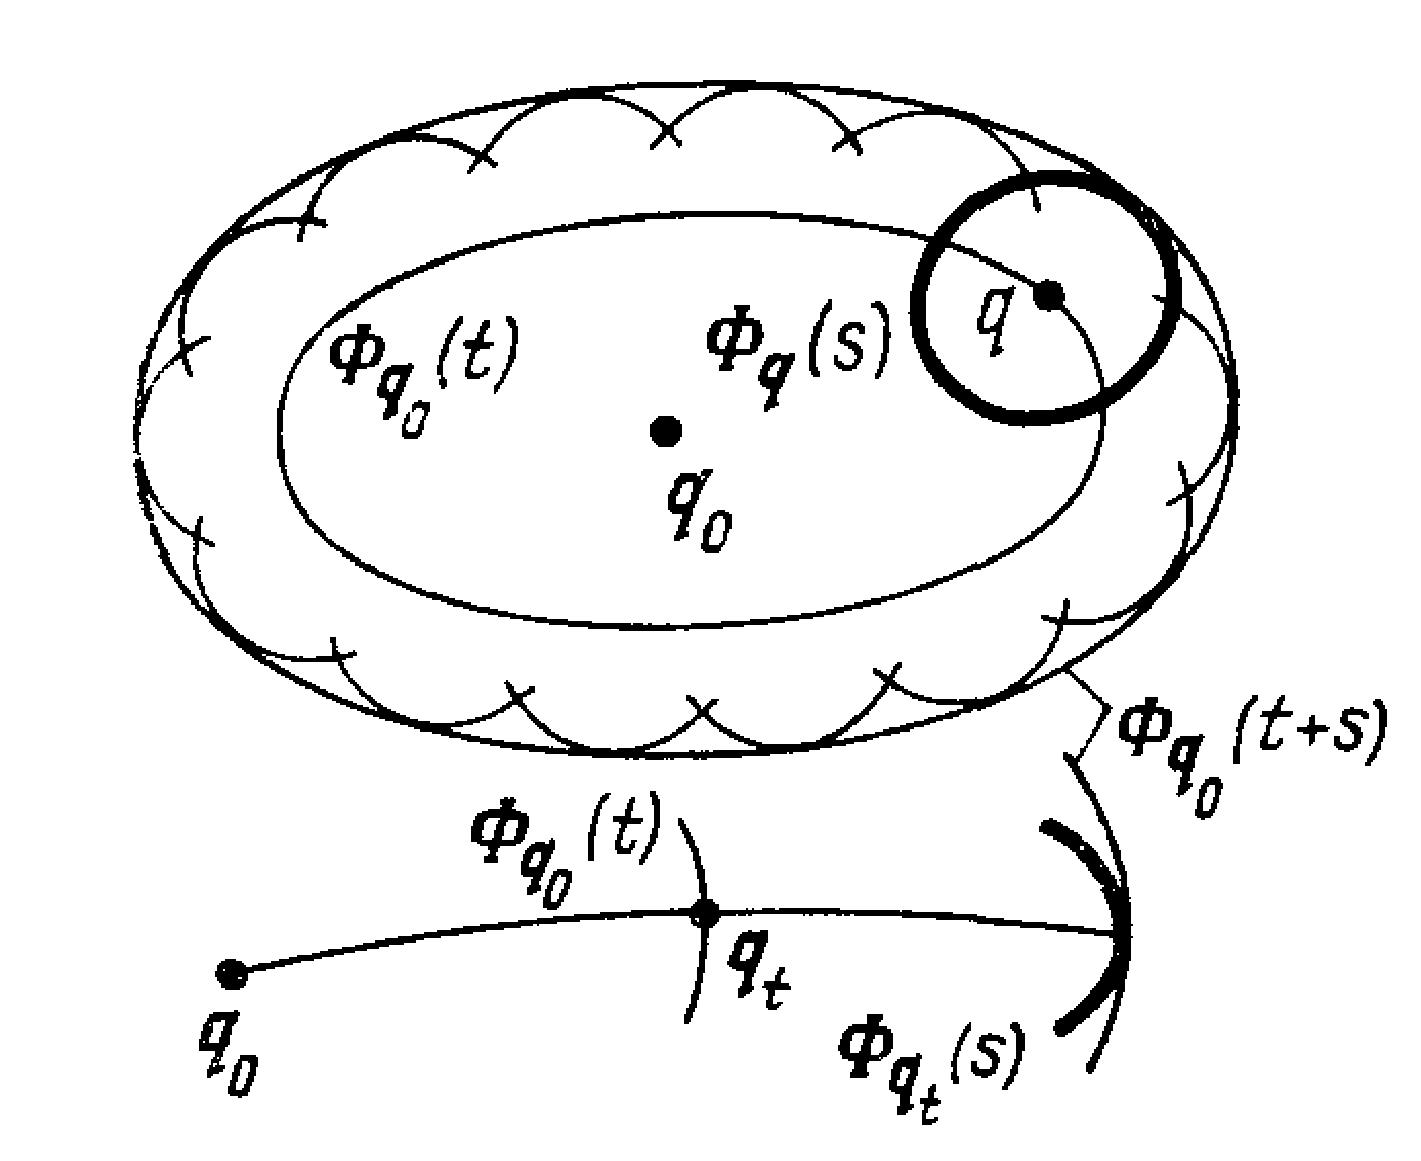



In anisotropic media in general the rays are not normal to the wave front. The wave front velocity (i.e. momentum) is determined by the conjugate direction. The conjugacy is due to local velocity ellipsoid characterized by the local electric permittivity tensor.


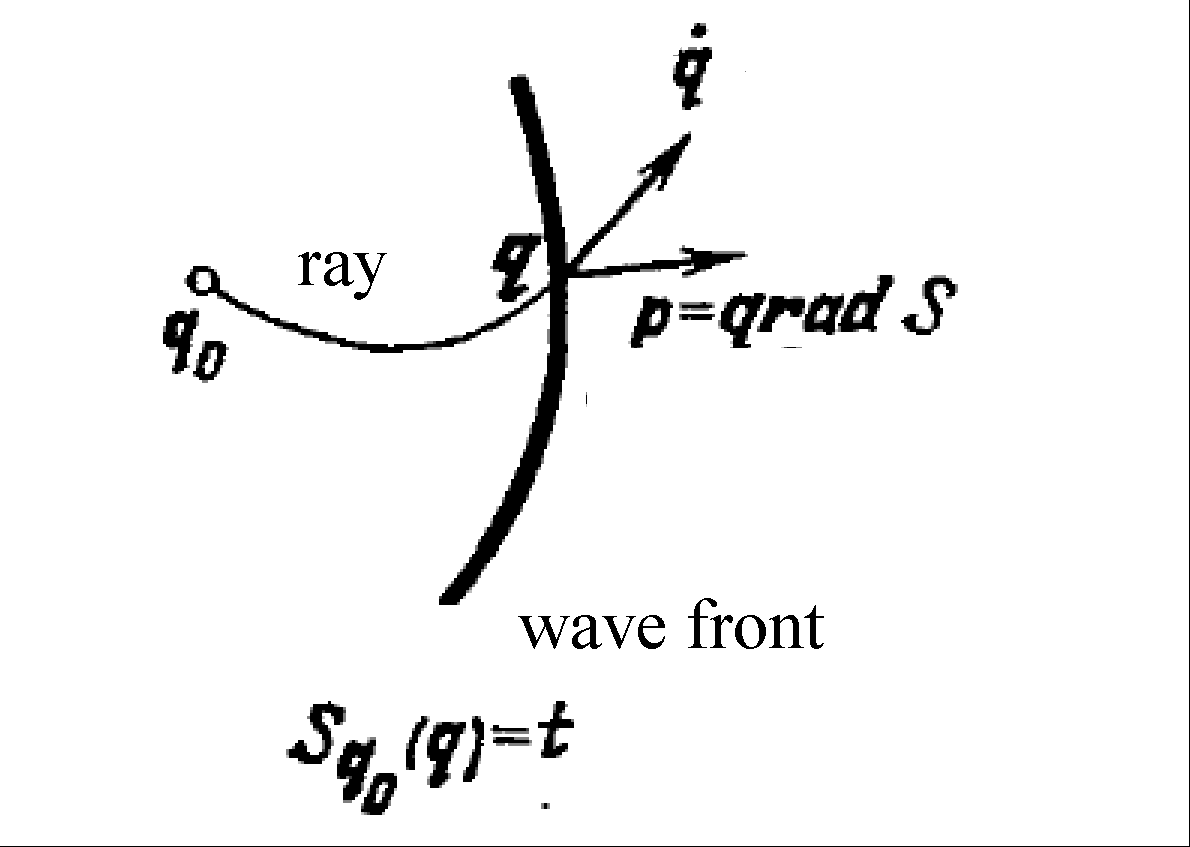



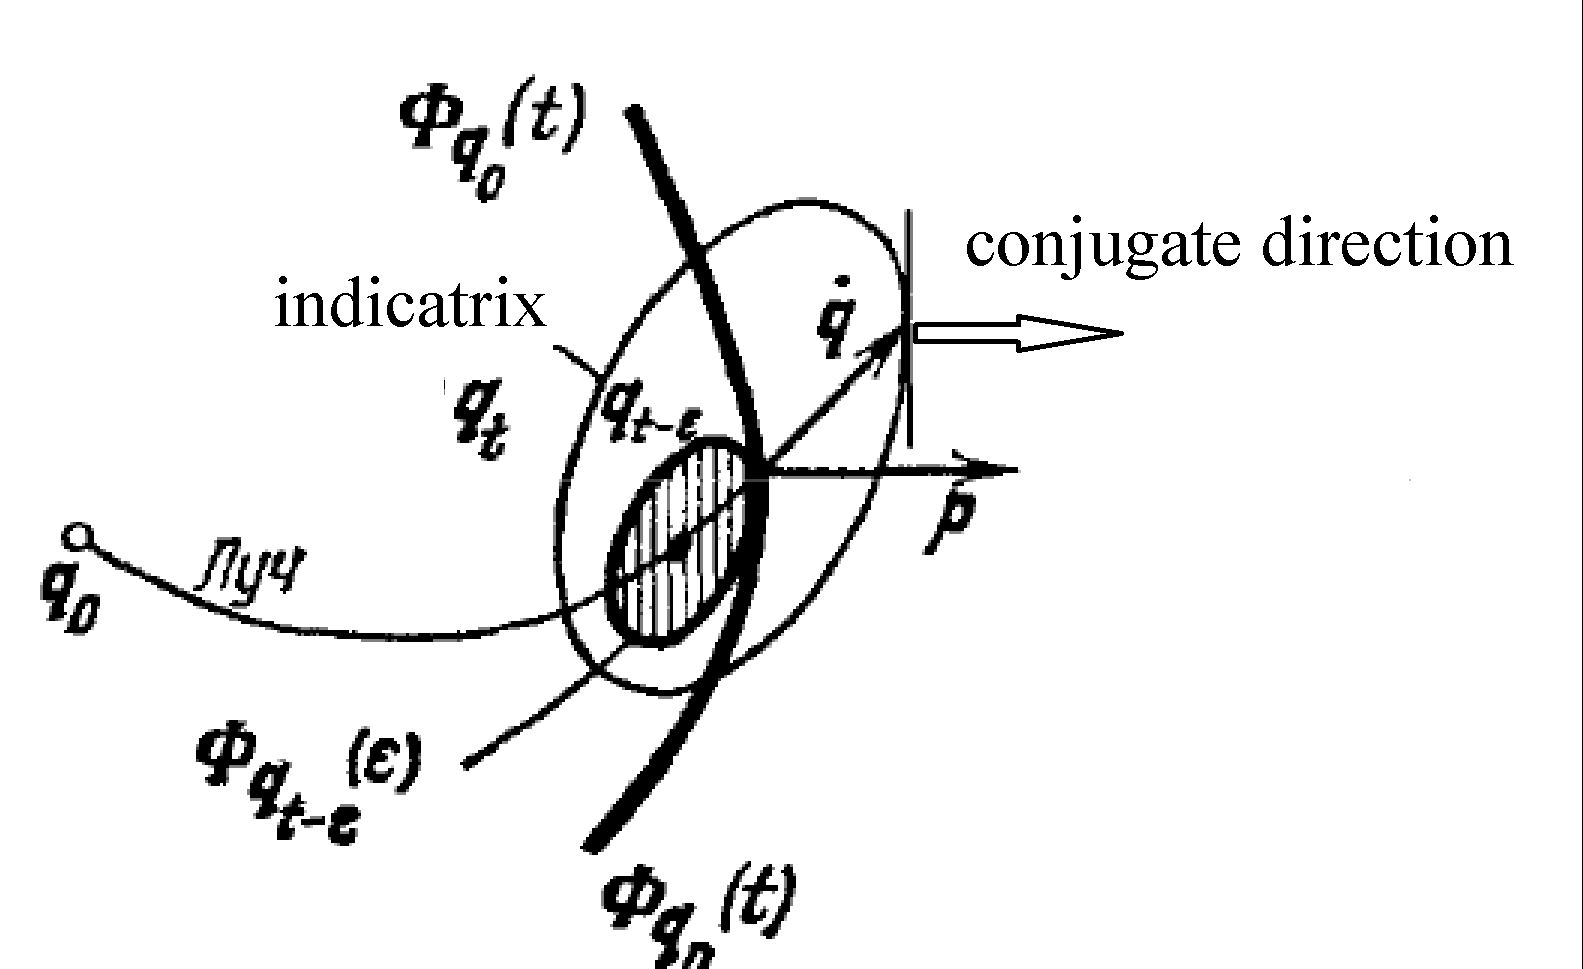



In an isotropic medium, rays follow the normals to the wavefront, and $\Phi$ acts as a potential for the field $\mathbf p=n\boldsymbol\tau$. A homogeneous medium provides a simple example: a parallel beam consists of parallel straight lines.

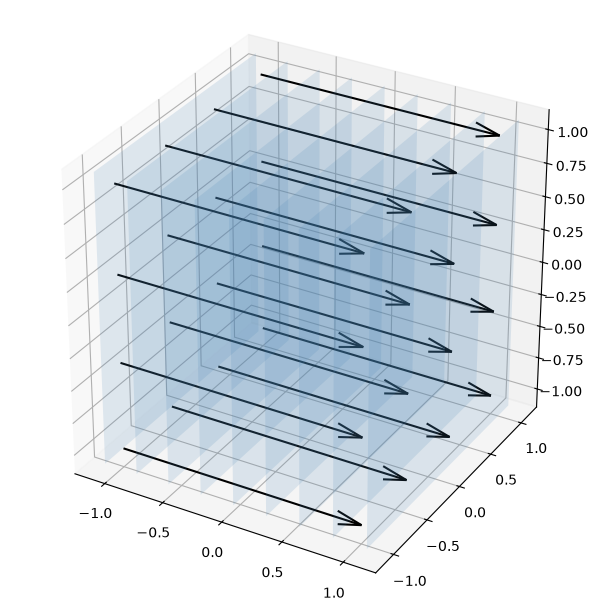

In [2]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
def sphere(ax,centre,radius,alpha=.15,color='gold',resolution=16):
    u,v=np.meshgrid(np.linspace(0,2*np.pi,resolution),np.linspace(0,np.pi,resolution//2))
    ax.plot_surface(centre[0]+radius*np.sin(v)*np.cos(u),centre[1]+radius*np.sin(v)*np.sin(u),centre[2]+radius*np.cos(v),color=color,alpha=alpha,linewidth=0)
fig=plt.figure(figsize=(7,6),layout='constrained'); ax=fig.add_subplot(projection='3d')
for y in np.linspace(-1,1,4):
    for z in np.linspace(-1,1,4): ax.quiver(-1,y,z,2,0,0,color='black',arrow_length_ratio=.1)
planes=[np.array([[-q,-1,-1],[-q,-1,1],[-q,1,1],[-q,1,-1]])*1.1 for q in np.arange(-1,1.01,.25)]
ax.add_collection3d(Poly3DCollection(planes,facecolor='steelblue',alpha=.15)); ax.set_box_aspect((1,1,1)); plt.show()

The ray direction is constant, so $\Phi\left(\mathbf r\right)$ is linear:

$$
\Phi =\mathbf{\tau }\mathbf{\cdot }\left(\mathbf{r}\mathbf{-}{\mathbf{r}}_{0}\right)\tag{3}
$$

For a point source, the wavefronts are concentric spheres:

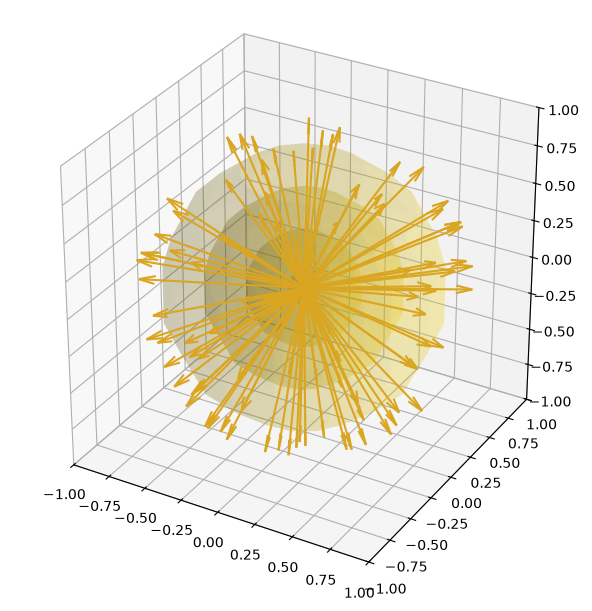

In [3]:
rng=np.random.default_rng(42)
rays=rng.uniform(-1,1,(100,3)); rays/=np.linalg.norm(rays,axis=1)[:,None]
fig=plt.figure(figsize=(7,6),layout='constrained'); ax=fig.add_subplot(projection='3d')
ax.quiver(np.zeros(100),np.zeros(100),np.zeros(100),*rays.T,color='goldenrod',arrow_length_ratio=.1)
for radius in np.arange(.1,1.01,.25): sphere(ax,(0,0,0),radius)
ax.set(xlim=(-1,1),ylim=(-1,1),zlim=(-1,1)); ax.set_box_aspect((1,1,1)); plt.show()

$$
\Phi =n \left(\left|\mathbf{r}\right|-\left|{\mathbf{r}}_{0}\right|\right)\tag{4}
$$

Note that parallel beam can be considered as coming from infinitely distant point-like source.

The wavefront construction leads to Huygens’ principle:

- Each point on a wavefront may be treated as a source of secondary spherical waves.

- At an obstacle, the secondary-wave construction must be combined with the boundary conditions at its surface.

In [4]:
# This input cell is empty in the original notebook.

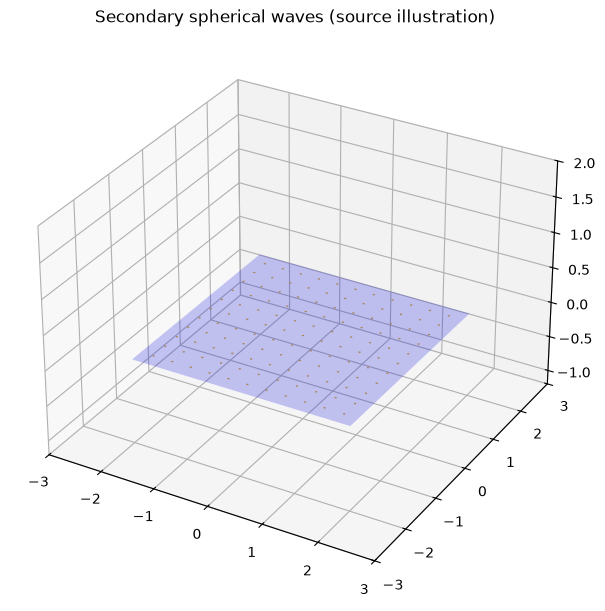

interactive(children=(FloatSlider(value=0.01, description='time', max=1.2, min=0.01, step=0.03), Output()), _d…

In [5]:
from itertools import product
centres=np.array([[x,y,0.] for x,y in product(np.linspace(-1.75,1.75,11),repeat=2)])
def show_secondary_waves(time=.01):
    fig=plt.figure(figsize=(8,6),layout='constrained'); ax=fig.add_subplot(projection='3d')
    for centre in centres: sphere(ax,centre,time,alpha=.06,resolution=12)
    ax.quiver(*centres.T,np.zeros(len(centres)),np.zeros(len(centres)),np.full(len(centres),1.5*time),color='goldenrod',arrow_length_ratio=.15)
    for height,color,alpha in [(0,'blue',.2),(time/2,'gray',np.sqrt(time)/2)]:
        face=np.array([[-2,-2,height],[2,-2,height],[2,2,height],[-2,2,height]])
        ax.add_collection3d(Poly3DCollection([face],facecolor=color,alpha=min(alpha,1)))
    ax.set(xlim=(-3,3),ylim=(-3,3),zlim=(-1.2,2),title='Secondary spherical waves (source illustration)'); ax.set_box_aspect((1,1,.7)); plt.show()
show_secondary_waves()
wave_controls=widgets.interactive(show_secondary_waves,time=widgets.FloatSlider(min=.01,max=1.2,value=.01,step=.03))
display(wave_controls)
# The source puts the grey plane at t/2 while sphere radii are t; it is not their envelope.

Thus the wave front “envelopes” all elementary secondary spherical ones.

## Mirror reflection from Huygens’ principle

The duality between rays and wave front allows to derive the laws of reflection and refraction using  the Huygens principle.

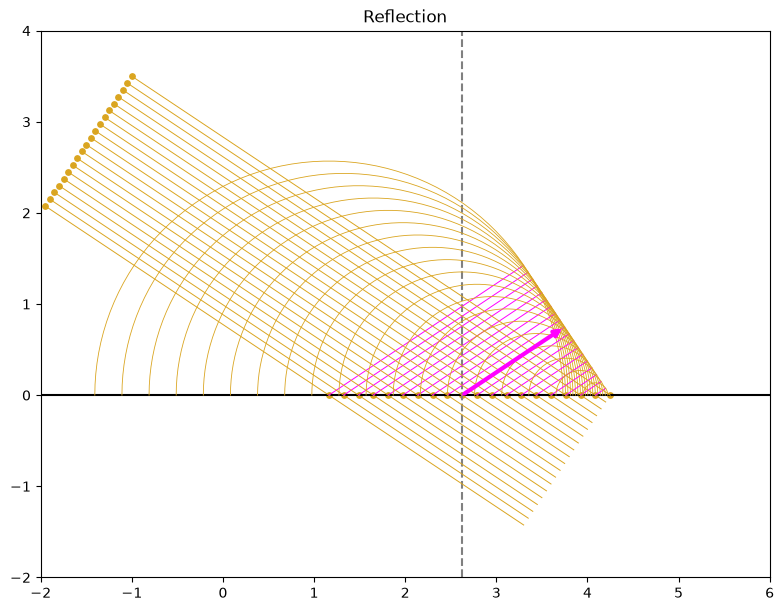

In [6]:
nn=np.array([1.5,-1.]); nnr=nn*np.array([1,-1]); normal=np.array([-nn[1],nn[0]])
p0=np.array([-2.,2.])+np.arange(1,21)[:,None]*normal/20
arrival=-p0[:,1]/nn[1]; impacts=p0+arrival[:,None]*nn
t02=arrival[9]; p02=impacts[9]
def reflected(time):
    points=p0+time*nn; points[:,1]=abs(points[:,1]); return points
def draw_optics(time,refracting=False):
    fig,ax=plt.subplots(figsize=(9,6),layout='constrained'); ax.axhline(0,color='black'); ax.axvline(p02[0],ls='--',color='gray')
    ax.scatter(*p0.T,color='goldenrod',s=15); ax.scatter(*impacts.T,color='goldenrod',s=15)
    points=p0+time*nn; out=reflected(time); radii=np.linalg.norm(out-impacts,axis=1)*(time>=arrival)
    for start,hit,point,ref,radius in zip(p0,impacts,points,out,radii):
        ax.plot([start[0],point[0]],[start[1],point[1]],color='goldenrod',lw=.7)
        ax.plot([hit[0],ref[0]],[hit[1],ref[1]],color='magenta',lw=.7)
        angle=np.linspace(0,np.pi,70); ax.plot(hit[0]+radius*np.cos(angle),hit[1]+radius*np.sin(angle),color='goldenrod',lw=.6,ls='--' if refracting else '-')
        if refracting: ax.plot(hit[0]+radius/2*np.cos(-angle),hit[1]+radius/2*np.sin(-angle),color='steelblue',lw=.7)
    elapsed=max(0,time-t02)
    ax.annotate('',xy=p02+elapsed*nnr,xytext=p02,arrowprops={'arrowstyle':'->','color':'magenta','lw':3})
    if refracting:
        # Preserve the source's illustrative direction, asin(1/nr), explicitly.
        direction=np.array([.5,-np.sqrt(3)/2])
        ax.annotate('',xy=p02+elapsed*direction,xytext=p02,arrowprops={'arrowstyle':'->','color':'blue','lw':3})
    ax.set(xlim=(-3,8) if refracting else (-2,6),ylim=(-4,4) if refracting else (-2,4),aspect='equal',title='Refraction' if refracting else 'Reflection'); plt.show()
reflection_controls=animate_parameter(lambda time:draw_optics(time),0,6,3.5,.05,'Time')

## Refraction from Huygens principle



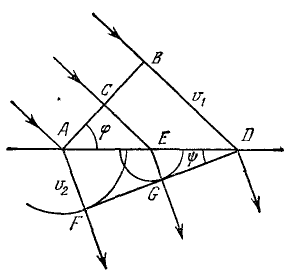



{'Source arrow angle (degrees)': np.float64(30.000000000000004),
 'Snell angle for this incident beam (degrees)': np.float64(24.583891486265475)}

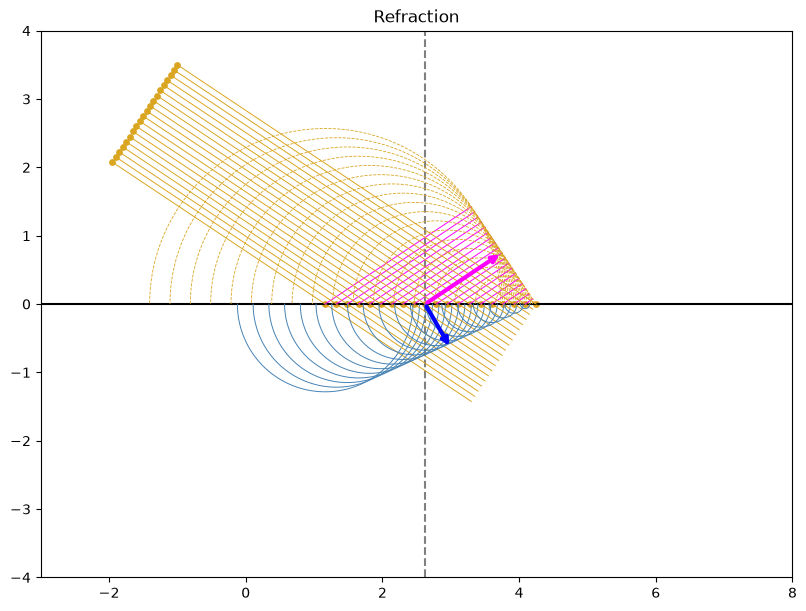

In [7]:
nr=2
source_refraction_angle=np.arcsin(1/nr)
snell_refraction_angle=np.arcsin(nn[0]/np.linalg.norm(nn)/nr)
# The original arrow uses source_refraction_angle; the wave circles obey the speed ratio.
display({'Source arrow angle (degrees)':np.degrees(source_refraction_angle),
         'Snell angle for this incident beam (degrees)':np.degrees(snell_refraction_angle)})
refraction_controls=animate_parameter(lambda time:draw_optics(time,True),0,6,3.5,.05,'Time')

If we consider the trajectories with fixed energy then their form is governed by the ``shortened`` least action

$$
{S}_{\text{mech}} = {\int }_{{q}_{0}}^{q}p dq={\int }_{{q}_{0}}^{q}\sqrt{2m\left(E-U\right)} ds={S}_{\text{opt}}={\int }_{{q}_{0}}^{q}n ds\\ n\leftrightarrow p=\sqrt{2m\left(E-U\right)}\to \sqrt{\left(1-U/E\right)}\tag{5}
$$

This is Maupertuis’ principle. It determines the paths of mechanical trajectories and, by analogy, light rays. The optical paths are geodesics of a metric conformally related to the Euclidean metric by the refractive index.

[Back to the course contents](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_TOC.ipynb)